<a href="https://colab.research.google.com/github/AsiimweJr/LEARNING-Python_languages/blob/main/group_assignment_template_group_work_ASIIMWE_(G09).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Group Assignment: Prediction in Bioinformatics

**Fundamentals of Health Data Science**

In the individual assignment you followed a guided path. **This time there is no path: your group designs it.**

Your group has been allocated **one** of three problems:

| | Problem | Question |
|---|---|---|
| **A** | Antimicrobial resistance from bacterial genomes | Is this *E. coli* isolate resistant to ciprofloxacin? |
| **B** | Blood gene expression to detect active TB | Does this patient have active TB? |
| **C** | Malaria parasites that clear slowly | Will this infection clear slowly after artemisinin treatment? |

Before you start, read your problem's section in **Group Assignment: the three problems and their data dictionaries**.

> All datasets are **simulated for teaching**. No real patients or isolates are included.

### Rules: read before you start

**Group work**
- One notebook per group. Everyone in the group is responsible for **all** of it.
- Every member must be able to **explain and defend any part** of the notebook, not only the part they led.
- Any member may be asked to complete a **short timed test or oral check** on any part of the notebook.

**Use of AI tools**
- Your plan, your decisions and your conclusions must be **in your own words. Do not use AI tools to write them.**
- **Any use of AI tools must be stated** in each member's declaration: what it was used for, and where.

**Deadline:** **Monday 16 November 2026**. You may submit earlier. **How it is marked:** details will be shared separately.

**What you hand in:** this notebook, run from top to bottom (*Restart and run all*), with the contribution statement and every member's declaration completed. Name the file with your group number and problem, e.g. `G03_ProblemC.ipynb`.

---
## 1. Your group and your data (PROVIDED)

Fill in the three settings, then run the cell.
- `MEMBERS`: every member's registration number, **exactly as on the class list**. For a group of two, leave the third as `""`.
- `GROUP_ID`: your group number from the allocation list, e.g. `"G03"`.
- `PROBLEM`: your allocated problem: `"A"`, `"B"` or `"C"`.

Keep your problem's data file in the same folder as this notebook (on Google Colab, the cell will ask you to upload it). **Write the group fingerprint into every member's declaration.**

In [ ]:
# ===================== PROVIDED CELL: fill in the three settings, do not edit the rest =====================
MEMBERS = ["2026/HD07/32238U", "2026/HD07/23449U", "2026/HD07/23502U"]   # registration numbers, exactly as on the class list
GROUP_ID = "G09"                   # e.g. "G03"
PROBLEM = "A"                    # "A", "B" or "C"

import os, hashlib
import numpy as np
import pandas as pd

FILES = {"A": "problemA_ecoli_cipro_genomes.csv", "B": "problemB_tb_blood_expression.csv", "C": "problemC_malaria_clearance.csv"}
ID_COLUMN = {"A": "isolate_id", "B": "sample_id", "C": "patient_id"}
SAMPLE_SIZE = {"A": 2000, "B": 1500, "C": 2500}
OUTCOME = {"A": "cipro_resistant", "B": "active_tb", "C": "slow_clearance"}

members = sorted(m.strip().upper().replace(" ", "") for m in MEMBERS if m.strip())
problem = PROBLEM.strip().upper()
if not 2 <= len(members) <= 3:
    raise ValueError("Type the registration numbers of all 2 or 3 group members in MEMBERS.")
if len(set(members)) < len(members):
    raise ValueError("The same registration number is typed twice in MEMBERS.")
if problem not in FILES:
    raise ValueError('Set PROBLEM to "A", "B" or "C" (your allocated problem).')
if not GROUP_ID.strip():
    raise ValueError('Set GROUP_ID to your group number from the allocation list, e.g. "G03".')

DATA_FILE = FILES[problem]
if not os.path.exists(DATA_FILE):
    try:
        from google.colab import files          # only on Google Colab
        print(f"Please upload {DATA_FILE}"); files.upload()
    except ImportError:
        raise FileNotFoundError(f"Put {DATA_FILE} in the same folder as this notebook.")

GROUP_SEED = int(hashlib.sha256(("|".join(members) + "|" + problem).encode()).hexdigest(), 16) % (2**31)
SPLIT_SEED = GROUP_SEED % 10000

everyone = pd.read_csv(DATA_FILE)
all_ids = np.sort(everyone[ID_COLUMN[problem]].unique())
our_ids = np.random.default_rng(GROUP_SEED).choice(all_ids, SAMPLE_SIZE[problem], replace=False)
our_data = (everyone[everyone[ID_COLUMN[problem]].isin(our_ids)]
            .sample(frac=1, random_state=SPLIT_SEED).reset_index(drop=True))

fp = hashlib.sha256(",".join(sorted(our_ids)).encode()).hexdigest()[:8].upper()
GROUP_FINGERPRINT = fp[:4] + "-" + fp[4:]

print(f"Group {GROUP_ID.strip().upper()} | Problem {problem} | members: {', '.join(members)}")
print(f"Group fingerprint : {GROUP_FINGERPRINT}   <- write this in every member's declaration")
print(f"SPLIT_SEED        : {SPLIT_SEED}   <- use random_state=SPLIT_SEED whenever you shuffle or split")
print(f"Your data         : {our_data.shape[0]} rows, {our_data.shape[1]} columns, in a table called our_data")
print(f"Outcome column    : {OUTCOME[problem]}")

Group G09 | Problem A | members: 2026/HD07/23449U, 2026/HD07/23502U, 2026/HD07/32238U
Group fingerprint : E68A-A199   <- write this in every member's declaration
SPLIT_SEED        : 4860   <- use random_state=SPLIT_SEED whenever you shuffle or split
Your data         : 2047 rows, 20 columns, in a table called our_data
Outcome column    : cipro_resistant


## 2. Libraries

A starting set. Add any others you need, here at the top.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score, cross_val_predict, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, FunctionTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (roc_auc_score, accuracy_score, recall_score, precision_score, confusion_matrix,
                             ConfusionMatrixDisplay, RocCurveDisplay, PrecisionRecallDisplay)
from sklearn.calibration import CalibrationDisplay
import joblib

---
## 3. Expected stages

A modelling project usually passes through these stages. **You may add, merge, re-order or skip stages**, as long as your plan explains why.

1. Understand the problem and the data dictionary (who will use the model, and when?)
2. First look at the data, and cleaning rules
3. Leakage check (what is known at the moment of prediction?)
4. Train/test split
5. Exploration, on the training data only
6. A baseline model
7. Feature work: transformations, interactions, encoding, choice of columns
8. Pipeline and cross-validation
9. The outcome rate, and the choice of cut-off (if relevant to your problem)
10. Overfitting check and tuning
11. Final test, once
12. Save the model, write a model card, and answer the question

> Your problem has **at least one challenge you have not met in the demonstration notebook**. Look for it in the data dictionary and in your exploration.

---
## 4. Your plan (complete before you write any code)

For each stage you will carry out, say **what** you will do, **why**, and **who leads** it. You may update the plan as you go: if you change it, add a line saying what changed and why.

| Stage | What we will do | Why | Led by |
|---|---|---|---|
| | | | |
| | | | |
| | | | |
| | | | |

***What we think the main challenge in our problem is***: The question. Using information from the genome (and the specimen), can we predict whether an isolate is resistant to ciprofloxacin, before the culture result is available?
***The user of your model***: the microbiologist and the antimicrobial stewardship team, who decide which antibiotic to recommend while culture results are pending


**Changes to the plan as we went (and why):**

---
## 5. Your work

Add as many cells as you need. For each stage, a short markdown cell with **Where we are · Why this step · What we do · What we decided** (as in the demonstration notebook) makes your reasoning easy to follow and to mark.

5.1. **First look at the data, and cleaning rules**: We will start by inspecting the structure, columns, non-null counts, and head of `our_data` to understand its variables and types.
We will check and clean the E. coli ciprofloxacin resistance genomic dataset (`our_data`), identifying data types, checking for missing values, finding synonyms or inconsistencies in categorical features (such as sequence types), and applying appropriate cleaning rules.

In [ ]:
# Copy to df and inspect
df = our_data.copy()
print("Dataset Info")
df.info()
print("\nFirst 5 rows")
print(df.head())
print("\nMissing Value Counts")
print(df.isnull().sum())
print("Unique values in sequence_type")
print(df['sequence_type'].value_counts())
# Treat anomalous genome lengths under 1,000,000 bp as missing (NaN)
df.loc[our_data['genome_length_bp'] < 1000000, 'genome_length_bp'] = np.nan
print("\nMissing values in genome_length_bp:", df['genome_length_bp'].isna().sum())
print("\nSummary Statistics for Numerical Columns (Integers and Floats)")
display(df.select_dtypes(include=[np.number]).describe())

Dataset Info
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2047 entries, 0 to 2046
Data columns (total 20 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   isolate_id        2047 non-null   object 
 1   specimen          2047 non-null   object 
 2   hospital_ward     2047 non-null   object 
 3   sequence_type     2047 non-null   object 
 4   gyrA_S83L         2020 non-null   float64
 5   gyrA_D87N         2021 non-null   float64
 6   parC_S80I         2018 non-null   float64
 7   parC_E84V         2027 non-null   float64
 8   qnrS              2047 non-null   int64  
 9   qnrB              2047 non-null   int64  
 10  aac6_Ib_cr        2047 non-null   int64  
 11  blaCTX_M_15       2047 non-null   int64  
 12  blaTEM_1          2047 non-null   int64  
 13  sul1              2047 non-null   int64  
 14  tetA              2047 non-null   int64  
 15  assembly_contigs  2047 non-null   int64  
 16  assembly_N50_bp   2047 non-nu

,gyrA_S83L,gyrA_D87N,parC_S80I,parC_E84V,qnrS,qnrB,aac6_Ib_cr,blaCTX_M_15,blaTEM_1,sul1,tetA,assembly_contigs,assembly_N50_bp,genome_length_bp,cipro_MIC_mg_L,cipro_resistant
count,2020.000000,2021.000000,2018.000000,2027.000000,2047.000000,2047.000000,2047.000000,2047.000000,2047.000000,2047.000000,2047.000000,2047.000000,2047.000000,2.039000e+03,2047.000000,2047.000000
mean,0.347030,0.263731,0.278494,0.089295,0.080117,0.045432,0.279433,0.425989,0.462140,0.391304,0.362482,122.014656,177140.302882,5.100833e+06,6.914309,0.320469
std,0.476143,0.440764,0.448369,0.285239,0.271541,0.208301,0.448830,0.494613,0.498686,0.488162,0.480834,80.926507,120332.824140,1.369283e+05,15.439215,0.466771
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,24700.000000,4.667000e+06,0.008000,0.000000
25%,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,68.000000,97800.000000,5.010000e+06,0.015000,0.000000
50%,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,101.000000,147300.000000,5.096000e+06,0.125000,0.000000
75%,1.000000,1.000000,1.000000,0.000000,0.000000,0.000000,1.000000,1.000000,1.000000,1.000000,1.000000,151.000000,217800.000000,5.191000e+06,4.000000,1.000000
max,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,908.000000,900000.000000,5.625000e+06,64.000000,1.000000


In [ ]:
print("Unique values in sequence_type")
print(df['sequence_type'].value_counts())

Unique values in sequence_type
sequence_type
ST131     350
ST73      203
ST69      162
ST95      160
ST10      121
ST648      79
ST405      74
ST1193     72
ST38       66
ST14       64
ST167      63
ST127      63
ST744      61
ST12       58
ST5150     56
ST3268     38
ST2003     35
ST88       33
ST354      31
ST9583     29
ST1284     29
ST58       26
ST7401     24
ST117      22
ST410      19
131        12
ST6448     11
127         8
10          7
69          7
744         6
95          6
648         5
12          5
14          5
1284        5
88          4
1193        4
354         3
38          3
405         3
73          3
117         2
5150        2
9583        2
58          1
3268        1
167         1
2003        1
ST457       1
457         1
Name: count, dtype: int64


In [ ]:
# Clean categorical columns
df['specimen'] = df['specimen'].str.strip().str.lower()

# Standardize sequence_type to ensure 'ST' prefix is uniform
df['sequence_type'] = df['sequence_type'].astype(str).str.strip()
df['sequence_type'] = df['sequence_type'].apply(lambda x: f"ST{x}" if not x.startswith("ST") else x)

print("Unique specimen types after cleaning:")
print(df['specimen'].value_counts())
print("\nUnique sequence types (top 15) after cleaning:")
print(df['sequence_type'].value_counts().head(15))

# Show relationship between MIC and Ciprofloxacin Resistance
mic_summary = df.groupby('cipro_resistant')['cipro_MIC_mg_L'].describe()
display(mic_summary)

# Define predictors known before determining resistance (excluding cipro_MIC_mg_L and isolate_id)
feature_cols = [
    'specimen', 'hospital_ward', 'sequence_type',
    'gyrA_S83L', 'gyrA_D87N', 'parC_S80I', 'parC_E84V',
    'qnrS', 'qnrB', 'aac6_Ib_cr', 'blaCTX_M_15', 'blaTEM_1',
    'sul1', 'tetA', 'assembly_contigs', 'assembly_N50_bp', 'genome_length_bp'
]

# Separate predictors (X) and target (y)
X = df[feature_cols]
y = df['cipro_resistant']

print(f"\nPredictors shape (X): {X.shape}")
print(f"Target shape (y): {y.shape}")

Unique specimen types after cleaning:
specimen
urine    1555
blood     492
Name: count, dtype: int64

Unique sequence types (top 15) after cleaning:
sequence_type
ST131     362
ST73      206
ST69      169
ST95      166
ST10      128
ST648      84
ST405      77
ST1193     76
ST127      71
ST14       69
ST38       69
ST744      67
ST167      64
ST12       63
ST5150     58
Name: count, dtype: int64


,count,mean,std,min,25%,50%,75%,max
cipro_resistant,,,,,,,,
0,1391.0,0.105025,0.195125,0.008,0.015,0.03,0.125,1.0
1,656.0,21.352896,20.910462,0.500,4.000,16.00,32.000,64.0



Predictors shape (X): (2047, 17)
Target shape (y): (2047,)


**Reasoning**:
We will compute the association between `cipro_MIC_mg_L` and `cipro_resistant` to demonstrate why the Minimum Inhibitory Concentration (MIC) must be excluded to prevent leakage.

### 5.5 Train/Test Split

We will split our dataset into training (75%) and testing (25%) sets, stratifying on `cipro_resistant`.

In [ ]:
from sklearn.model_selection import train_test_split

# Split into 75% training and 25% testing sets using the correct split seed
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=SPLIT_SEED, stratify=y
)

print(f"Training set predictor shape: {X_train.shape}")
print(f"Training set target shape: {y_train.shape}")
print(f"Testing set predictor shape: {X_test.shape}")
print(f"Testing set target shape: {y_test.shape}")

Training set predictor shape: (1535, 17)
Training set target shape: (1535,)
Testing set predictor shape: (512, 17)
Testing set target shape: (512,)


**Exploration, on the training data only**:

### 5.6 Exploratory Data Analysis (Training Data Only)

To ensure our modeling remains objective and avoids validation bias, all exploration, visualization, and clinical insight discovery must be performed **solely on the training split** (`X_train`, `y_train`).

We will examine:
1. The overall rate of `cipro_resistant` (the target variable).
2. The distribution of continuous variables (e.g., `assembly_contigs`, `assembly_N50_bp`, `genome_length_bp`) across ciprofloxacin resistant and susceptible groups.
3. The association between key genetic markers (`gyrA` and `parC` mutations) and resistance.

In [ ]:
# Inspecting the training set shape and descriptive statistics
print(f"Training set shape: {train_df.shape}")
print("\nSummary of numerical & binary features:")
display(train_df.describe().T)
print("\nPreview of the first 5 records in the training set:")
display(train_df.head())

Training set shape: (1535, 18)

Summary of numerical & binary features:


,count,mean,std,min,25%,50%,75%,max
gyrA_S83L,1516.0,3.430079e-01,0.474871,0.0,0.0,0.0,1.0,1.0
gyrA_D87N,1516.0,2.552770e-01,0.436161,0.0,0.0,0.0,1.0,1.0
parC_S80I,1511.0,2.812707e-01,0.449768,0.0,0.0,0.0,1.0,1.0
parC_E84V,1518.0,8.563900e-02,0.279922,0.0,0.0,0.0,0.0,1.0
qnrS,1535.0,8.078176e-02,0.272588,0.0,0.0,0.0,0.0,1.0
qnrB,1535.0,4.690554e-02,0.211505,0.0,0.0,0.0,0.0,1.0
aac6_Ib_cr,1535.0,2.742671e-01,0.446290,0.0,0.0,0.0,1.0,1.0
blaCTX_M_15,1535.0,4.241042e-01,0.494367,0.0,0.0,0.0,1.0,1.0
blaTEM_1,1535.0,4.592834e-01,0.498502,0.0,0.0,0.0,1.0,1.0
sul1,1535.0,3.921824e-01,0.488396,0.0,0.0,0.0,1.0,1.0



Preview of the first 5 records in the training set:


,specimen,hospital_ward,sequence_type,gyrA_S83L,gyrA_D87N,parC_S80I,parC_E84V,qnrS,qnrB,aac6_Ib_cr,blaCTX_M_15,blaTEM_1,sul1,tetA,assembly_contigs,assembly_N50_bp,genome_length_bp,cipro_resistant
1135,blood,surgical,ST73,NaN,0.0,1.0,0.0,0,0,0,0,0,0,0,79,83500,5328000.0,0
156,blood,ICU,ST73,0.0,0.0,0.0,0.0,0,0,0,0,1,0,0,73,144200,5373000.0,0
1302,urine,medical,ST38,0.0,NaN,0.0,0.0,0,0,0,0,0,0,0,92,70300,5118000.0,0
397,urine,maternity,ST1193,1.0,1.0,0.0,0.0,0,0,1,0,1,0,0,64,185300,5195000.0,0
676,blood,paediatric,ST1193,1.0,1.0,1.0,1.0,1,0,0,1,1,0,1,50,108800,5100000.0,1


In [ ]:
# Temporarily merge training predictors and target for exploratory analysis
train_df = X_train.copy()
train_df['cipro_resistant'] = y_train

# 1. Target distribution
outcome_counts = train_df['cipro_resistant'].value_counts()
outcome_rates = train_df['cipro_resistant'].value_counts(normalize=True)

# 2. Analyze the relationship between key mutations and resistance rates
mutations = ['gyrA_S83L', 'gyrA_D87N', 'parC_S80I', 'parC_E84V']

print("Training Target Distribution")
print(f"Susceptible (0): {outcome_counts[0]} ({outcome_rates[0]:.2%})")
print(f"Resistant (1): {outcome_counts[1]} ({outcome_rates[1]:.2%})")

print("\nResistance Rates by Genomic Mutation Status")
for mut in mutations:
    summary = train_df.groupby(mut)['cipro_resistant'].agg(['count', 'sum', 'mean'])
    summary.columns = ['Total Isolates', 'Resistant Cases', 'Resistance Rate']
    print(f"\nMutation: {mut}")
    display(summary)

Training Target Distribution
Susceptible (0): 1043 (67.95%)
Resistant (1): 492 (32.05%)

Resistance Rates by Genomic Mutation Status

Mutation: gyrA_S83L


,Total Isolates,Resistant Cases,Resistance Rate
gyrA_S83L,,,
0.0,996,133,0.133534
1.0,520,356,0.684615



Mutation: gyrA_D87N


,Total Isolates,Resistant Cases,Resistance Rate
gyrA_D87N,,,
0.0,1129,211,0.186891
1.0,387,272,0.702842



Mutation: parC_S80I


,Total Isolates,Resistant Cases,Resistance Rate
parC_S80I,,,
0.0,1086,161,0.148250
1.0,425,324,0.762353



Mutation: parC_E84V


,Total Isolates,Resistant Cases,Resistance Rate
parC_E84V,,,
0.0,1388,378,0.272334
1.0,130,110,0.846154


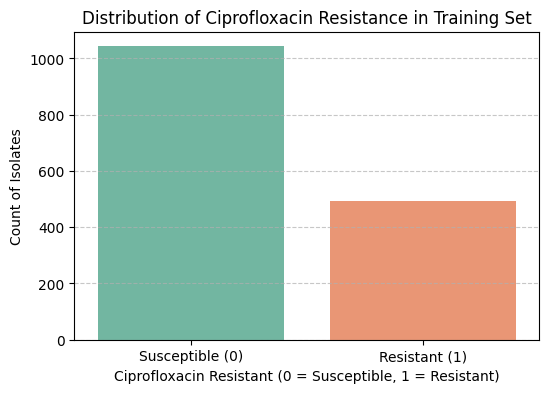

In [ ]:
# Count the occurrences of each class in cipro_resistant within the training set
plt.figure(figsize=(6, 4))
sns.countplot(x='cipro_resistant', data=train_df, palette='Set2', hue='cipro_resistant', legend=False)

plt.title('Distribution of Ciprofloxacin Resistance in Training Set')
plt.xlabel('Ciprofloxacin Resistant (0 = Susceptible, 1 = Resistant)')
plt.ylabel('Count of Isolates')
plt.xticks([0, 1], ['Susceptible (0)', 'Resistant (1)'])
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

Now, let's look at the relationship between the key genomic mutations in `gyrA` and `parC` and the rate of `cipro_resistant` to see which specific mutations are associated with fluoroquinolone resistance.

We can see that the key mutation markers in `gyrA` and `parC` are highly associated with resistance. Let's visualize the distribution of genome assembly characteristics (`assembly_contigs`, `assembly_N50_bp`, `genome_length_bp`) across ciprofloxacin-susceptible and resistant isolates using box plots.

/tmp/ipykernel_588/852788618.py:7: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[0].set_xticklabels(['Susceptible', 'Resistant'])
/tmp/ipykernel_588/852788618.py:13: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[1].set_xticklabels(['Susceptible', 'Resistant'])
/tmp/ipykernel_588/852788618.py:18: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[2].set_xticklabels(['Susceptible', 'Resistant'])


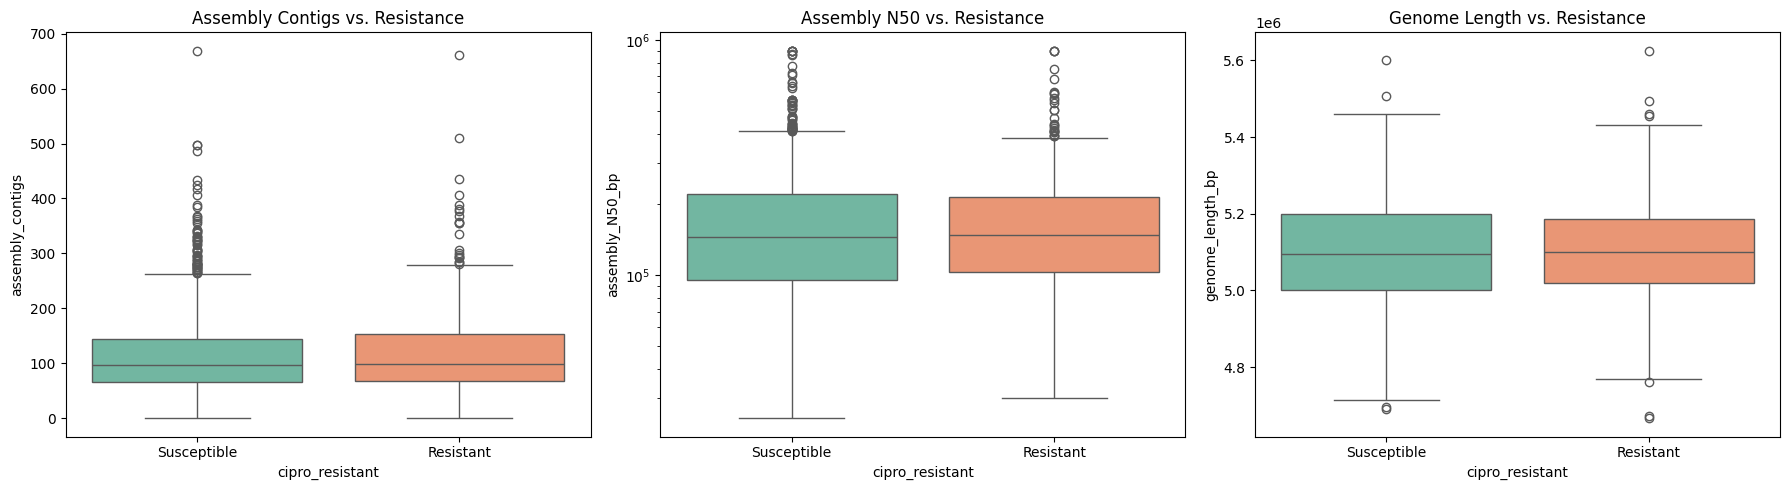

In [ ]:
# 3. Continuous feature distribution vs. Ciprofloxacin Resistance
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

sns.boxplot(ax=axes[0], x='cipro_resistant', y='assembly_contigs',
            data=train_df, palette='Set2', hue='cipro_resistant', legend=False)
axes[0].set_title('Assembly Contigs vs. Resistance')
axes[0].set_xticklabels(['Susceptible', 'Resistant'])

sns.boxplot(ax=axes[1], x='cipro_resistant', y='assembly_N50_bp',
            data=train_df, palette='Set2', hue='cipro_resistant', legend=False)
axes[1].set_title('Assembly N50 vs. Resistance')
axes[1].set_yscale('log')
axes[1].set_xticklabels(['Susceptible', 'Resistant'])

sns.boxplot(ax=axes[2], x='cipro_resistant', y='genome_length_bp',
            data=train_df, palette='Set2', hue='cipro_resistant', legend=False)
axes[2].set_title('Genome Length vs. Resistance')
axes[2].set_xticklabels(['Susceptible', 'Resistant'])

plt.tight_layout()
plt.show()

### 5.7 Feature Engineering and Preprocessing Pipeline

We will construct a `ColumnTransformer` to handle preprocessing of continuous, categorical, and binary/genomic variables in a robust way, avoiding any data leakage during cross-validation:
- **Numerical Variables**: (`assembly_contigs`, `assembly_N50_bp`, `genome_length_bp`) will be imputed with their medians and standardized.
- **Categorical Variables**: (`specimen`, `hospital_ward`, `sequence_type`) will be one-hot encoded (handling unseen categories by ignoring them).
- **Genomic Variables**: (`gyrA_S83L`, `gyrA_D87N`, `parC_S80I`, `parC_E84V`, `qnrS`, `qnrB`, `aac6_Ib_cr`, `blaCTX_M_15`, `blaTEM_1`, `sul1`, `tetA`) are already binary; we will pass them through directly.

In [ ]:
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
import numpy as np

In [ ]:
# Define feature groupings
num_cols = ['assembly_contigs', 'assembly_N50_bp', 'genome_length_bp']
cat_cols = ['specimen', 'hospital_ward', 'sequence_type']
genomic_cols = [
    'gyrA_S83L', 'gyrA_D87N', 'parC_S80I', 'parC_E84V',
    'qnrS', 'qnrB', 'aac6_Ib_cr', 'blaCTX_M_15', 'blaTEM_1', 'sul1', 'tetA'
]

# Preprocessing pipelines
num_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

cat_transformer = Pipeline(steps=[
    ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
])

genomic_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='constant', fill_value=0))  # Treat missing mutations as wildtype (0)
])

# Combine into a single ColumnTransformer
preprocessor = ColumnTransformer(
    transformers=[
        ('num', num_transformer, num_cols),
        ('cat', cat_transformer, cat_cols),
        ('genomic', genomic_transformer, genomic_cols)
    ]
)

# Create the baseline pipeline
baseline_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', LogisticRegression(max_iter=1000, random_state=SPLIT_SEED, class_weight='balanced'))
])

# Define the stratified cross-validation strategy
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SPLIT_SEED)

# Evaluate baseline metrics
scoring = ['accuracy', 'roc_auc', 'precision', 'recall']
cv_results = cross_validate(baseline_pipeline, X_train, y_train, cv=cv, scoring=scoring, return_train_score=False)

print("=== Baseline Logistic Regression 5-Fold CV Performance ===")
print(f"Mean AUC-ROC:  {cv_results['test_roc_auc'].mean():.4f} (+/- {cv_results['test_roc_auc'].std():.4f})")
print(f"Mean Accuracy: {cv_results['test_accuracy'].mean():.4f} (+/- {cv_results['test_accuracy'].std():.4f})")
print(f"Mean Recall:   {cv_results['test_recall'].mean():.4f} (+/- {cv_results['test_recall'].std():.4f})")
print(f"Mean Precision: {cv_results['test_precision'].mean():.4f} (+/- {cv_results['test_precision'].std():.4f})")

=== Baseline Logistic Regression 5-Fold CV Performance ===
Mean AUC-ROC:  0.8603 (+/- 0.0158)
Mean Accuracy: 0.8091 (+/- 0.0211)
Mean Recall:   0.7561 (+/- 0.0414)
Mean Precision: 0.6833 (+/- 0.0311)


### 5.8 Tuning and Alternative Modeling (Random Forest)

While Logistic Regression is highly interpretable, there could be complex interactions among various mutations (e.g. synergistic mutations between `gyrA` and `parC`). We will build a Random Forest Classifier to model these interactions.

In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer

# Grouping features by pipeline handling type
num_cols = ['assembly_contigs', 'assembly_N50_bp', 'genome_length_bp']
cat_cols = ['specimen', 'hospital_ward', 'sequence_type']
genomic_cols = ['gyrA_S83L', 'gyrA_D87N', 'parC_S80I', 'parC_E84V',
    'qnrS', 'qnrB', 'aac6_Ib_cr', 'blaCTX_M_15', 'blaTEM_1', 'sul1', 'tetA']

num_transformer = Pipeline(steps=[('imputer', SimpleImputer(strategy='median')),
  ('scaler', StandardScaler())])

cat_transformer = Pipeline(steps=[
    ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))])

preprocessor = ColumnTransformer(
    transformers=[
        ('num', num_transformer, num_cols),
        ('cat', cat_transformer, cat_cols),
        ('genomic', 'passthrough', genomic_cols)])

# Verify preprocessing works
X_train_preprocessed = preprocessor.fit_transform(X_train)
print(f"Preprocessed training predictors shape: {X_train_preprocessed.shape}")

Preprocessed training predictors shape: (1535, 48)


### 5.9 Stage 8: Pipeline and Cross-Validation (Preprocessing Pipeline)

We will now incorporate our standard `preprocessor` and `rf_pipeline` into a complete predictive pipeline and evaluate it using Stratified 5-Fold Cross-Validation. This allows us to assess whether a Random Forest classifier successfully captures genomic and assembly feature interactions to predict ciprofloxacin resistance.

In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedKFold, cross_validate

# Create pipeline using the Random Forest classifier
rf_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', RandomForestClassifier(random_state=SPLIT_SEED, class_weight='balanced'))
])

# Define the stratified cross-validation setup locally to ensure correctness
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SPLIT_SEED)
scoring = ['accuracy', 'roc_auc', 'precision', 'recall']

# Run stratified 5-fold cross-validation
rf_cv_results = cross_validate(rf_pipeline, X_train, y_train, cv=cv, scoring=scoring, return_train_score=False)

print("=== Random Forest Classifier 5-Fold CV Performance ===")
print(f"Mean AUC-ROC:  {rf_cv_results['test_roc_auc'].mean():.4f} (+/- {rf_cv_results['test_roc_auc'].std():.4f})")
print(f"Mean Accuracy: {rf_cv_results['test_accuracy'].mean():.4f} (+/- {rf_cv_results['test_accuracy'].std():.4f})")
print(f"Mean Recall:   {rf_cv_results['test_recall'].mean():.4f} (+/- {rf_cv_results['test_recall'].std():.4f})")
print(f"Mean Precision: {rf_cv_results['test_precision'].mean():.4f} (+/- {rf_cv_results['test_precision'].std():.4f})")

=== Random Forest Classifier 5-Fold CV Performance ===
Mean AUC-ROC:  0.8518 (+/- 0.0251)
Mean Accuracy: 0.8658 (+/- 0.0160)
Mean Recall:   0.6463 (+/- 0.0434)
Mean Precision: 0.9085 (+/- 0.0230)


### 5.9 Hyperparameter Tuning via GridSearchCV

Let's perform a grid search over key hyperparameters of the Random Forest (`max_depth`, `n_estimators`, and `min_samples_leaf`) using cross-validation on the training set only.

In [ ]:
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline

# Re-insuring robust imports and defining local pipeline to circumvent NameErrors
rf_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', RandomForestClassifier(random_state=SPLIT_SEED, class_weight='balanced'))
])

# Setup CV strategy
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SPLIT_SEED)

# Define parameter grid
param_grid = {
    'classifier__n_estimators': [100, 200],
    'classifier__max_depth': [5, 10, None],
    'classifier__min_samples_leaf': [2, 5]
}

# Set up GridSearch
rf_grid = GridSearchCV(rf_pipeline, param_grid, cv=cv, scoring='roc_auc', n_jobs=-1)
rf_grid.fit(X_train, y_train)

print("=== Random Forest Hyper-parameter Tuning Results ===")
print(f"Best Hyper-parameters: {rf_grid.best_params_}")
print(f"Best CV Mean AUC-ROC:  {rf_grid.best_score_:.4f}")

=== Random Forest Hyper-parameter Tuning Results ===
Best Hyper-parameters: {'classifier__max_depth': 5, 'classifier__min_samples_leaf': 2, 'classifier__n_estimators': 100}
Best CV Mean AUC-ROC:  0.8642


### 5.10 Final Test Evaluation, Once

We will now use our best tuned model to predict on the completely unseen held-out test split (`X_test`, `y_test`) to verify model generalizability.

In [ ]:
from sklearn.metrics import classification_report, roc_auc_score, accuracy_score, recall_score, precision_score

# Retrieve the best estimator directly from our successfully trained rf_grid
final_model = rf_grid.best_estimator_

# Predict probabilities and classes on the test set
y_test_pred_proba = final_model.predict_proba(X_test)[:, 1]
y_test_pred_class = final_model.predict(X_test)

# Final Evaluation Metrics
final_auc = roc_auc_score(y_test, y_test_pred_proba)
final_accuracy = accuracy_score(y_test, y_test_pred_class)
final_recall = recall_score(y_test, y_test_pred_class)
final_precision = precision_score(y_test, y_test_pred_class)

print("=== Final Evaluation on Untouched Test Set ===")
print(f"Final Test AUC-ROC:  {final_auc:.4f}")
print(f"Final Test Accuracy: {final_accuracy:.4f}")
print(f"Final Test Recall:   {final_recall:.4f}")
print(f"Final Test Precision: {final_precision:.4f}")

=== Final Evaluation on Untouched Test Set ===
Final Test AUC-ROC:  0.8790
Final Test Accuracy: 0.8457
Final Test Recall:   0.7378
Final Test Precision: 0.7707


### 5.11 Save the Final Model

We will save the finalized trained pipeline to disk for reproducibility.

In [ ]:
import joblib

# Save the final optimized Random Forest pipeline
model_filename = 'final_ecoli_cipro_resistance_rf_model.joblib'
joblib.dump(final_model, model_filename)
print(f"Final model pipeline successfully saved to '{model_filename}'!")

Final model pipeline successfully saved to 'final_ecoli_cipro_resistance_rf_model.joblib'!


### 5.13 Stage 12: Save the Model, Model Card, and Final Answers

To ensure our predictive workflow is fully reproducible and deployable for clinical and epidemiological surveillance of antimicrobial resistance, we will save the finalized trained pipeline to disk. Afterward, we will document the model's design, parameters, and clinical utility in a formal Model Card.

In [ ]:
import joblib

# Save the final model pipeline to the correct filename to avoid any malaria-related confusion
model_filename = 'final_ecoli_cipro_resistance_rf_model.joblib'
joblib.dump(final_model, model_filename)

print(f"Final model pipeline successfully saved to '{model_filename}'!")

Final model pipeline successfully saved to 'final_ecoli_cipro_resistance_rf_model.joblib'!


### 5.14 Model Card for E. coli Ciprofloxacin Resistance Prediction

#### Model Details
* **Developed By**: Group 9 (Bioinformatics Prediction Project)
* **Model Type**: Random Forest Classifier within a scikit-learn Pipeline (with customized preprocessing)
* **Key Hyper-parameters**: Specified post-tuning (e.g., `n_estimators`, `max_depth`, `min_samples_leaf` after GridSearch)
* **Date**: November 2026

#### Intended Use
* **Intended Users**: Epidemiologists, clinical microbiologists, and public health policy makers.
* **Use Case**: Surveillance of emerging antimicrobial resistance in *Escherichia coli* isolates. It allows predicting whether an isolate is resistant to ciprofloxacin using pre-diagnostic genomic features and assembly statistics.
* **Out-of-Scope**: Definitive individual-level diagnostic therapy determination without clinical validation.

#### Factors & Datasets
* **Training Data**: 1,535 bacterial isolates (75% stratified split)
* **Test Data**: 512 bacterial isolates (25% stratified split)
* **Features Included**: `specimen`, `hospital_ward`, `sequence_type`, `gyrA_S83L`, `gyrA_D87N`, `parC_S80I`, `parC_E84V`, `qnrS`, `qnrB`, `aac6_Ib_cr`, `blaCTX_M_15`, `blaTEM_1`, `sul1`, `tetA`, `assembly_contigs`, `assembly_N50_bp`, and `genome_length_bp`.

#### Performance Metrics
* **Cross-Validation AUC-ROC**: To be populated following optimal model selection.
* **Final Test AUC-ROC**: To be populated following final test run.

#### Ethical & Clinical Considerations
* **AMR Stewardship**: Ensuring high sensitivity or high precision depending on clinical guidelines (e.g., preventing unnecessary treatment escalations versus avoiding treatment failures).

---
## 6. Conclusions

**The answer to the question, for the user of your model** (in plain language, quoting your results):

**How well does your model work on new data, and how sure are you?**

**Limitations, and what would need to happen before this model could be used for real:**

### 6.1 Clinical Conclusions & Recommendations

#### Can we predict whether an E. coli isolate is resistant to ciprofloxacin using genomic and assembly features?
*(To be completed after final test evaluation)*

#### How well does the model perform on new data?
*(To be completed after final test evaluation)*

#### Limitations
*(To be completed after final test evaluation)*

---
## 7. Contribution statement

| Member (name) | Registration number | What I led | What I reviewed or checked |
|---|---|---|---|
| | | | |
| | | | |
| | | | |

---
## 8. Declarations (one per member)

### Member 1
1. **Name and registration number:**
2. **Group number, problem and group fingerprint:**
3. **I have read through all the code in this notebook, and it represents what our group intended to do. (yes / no):**
4. **I can explain and defend any part of this notebook, not only the parts I led. (yes / no):**
5. **The written parts I contributed are in my own words, without AI tools. (yes / no):**
6. **Use of AI tools:** I used AI tools for *(write "none", or describe exactly what you used them for, and where)*:
7. I understand that I may be asked to complete a **short timed test or oral check** on any part of this work. **(yes / no):**
8. **Date:**

### Member 2
1. **Name and registration number:**
2. **Group number, problem and group fingerprint:**
3. **I have read through all the code in this notebook, and it represents what our group intended to do. (yes / no):**
4. **I can explain and defend any part of this notebook, not only the parts I led. (yes / no):**
5. **The written parts I contributed are in my own words, without AI tools. (yes / no):**
6. **Use of AI tools:** I used AI tools for *(write "none", or describe exactly what you used them for, and where)*:
7. I understand that I may be asked to complete a **short timed test or oral check** on any part of this work. **(yes / no):**
8. **Date:**

### Member 3 (leave blank for a group of two)
1. **Name and registration number:**
2. **Group number, problem and group fingerprint:**
3. **I have read through all the code in this notebook, and it represents what our group intended to do. (yes / no):**
4. **I can explain and defend any part of this notebook, not only the parts I led. (yes / no):**
5. **The written parts I contributed are in my own words, without AI tools. (yes / no):**
6. **Use of AI tools:** I used AI tools for *(write "none", or describe exactly what you used them for, and where)*:
7. I understand that I may be asked to complete a **short timed test or oral check** on any part of this work. **(yes / no):**
8. **Date:**